In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/core_financials.csv')
df_copy = df.copy()
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Exploratory data analysis

The analysis is designed to update automatically as new clubs and fiscal years are added. Interpretive findings refer to the current dataset and should be reviewed when the data is updated.

## Dataset overview

In [2]:
df_copy[['club', 'fiscal_year']].nunique()

club           35
fiscal_year    10
dtype: int64

In [3]:
df_copy['fiscal_year'].value_counts().sort_index()

fiscal_year
2016    33
2017    33
2018    33
2019    33
2020    35
2021    35
2022    35
2023    35
2024    34
2025    33
Name: count, dtype: int64

## Core financial variables

In [4]:
df_copy.drop(columns=['club', 'fiscal_year']).describe()

,cash,current_assets,total_assets,current_liabilities,total_liabilities,equity,net_result
count,339.00,339.00,339.00,339.00,339.00,339.00,339.00
mean,14313.36,79729.60,431541.61,189206.37,445034.38,-13492.77,-10789.49
std,33055.64,121243.68,545266.06,247622.67,503130.73,276808.17,93129.63
min,0.00,0.00,845.03,377.67,377.67,-869319.00,-882109.00
25%,410.12,6690.87,65511.22,20041.71,69830.01,-99757.50,-24864.91
50%,2593.00,27574.42,213854.85,76522.00,243397.00,-1621.92,-1503.07
75%,12844.79,92947.00,589017.00,270273.36,738284.00,77334.79,14008.67
max,236887.00,665121.00,3283083.00,1355603.00,2757292.00,1129434.00,383268.00


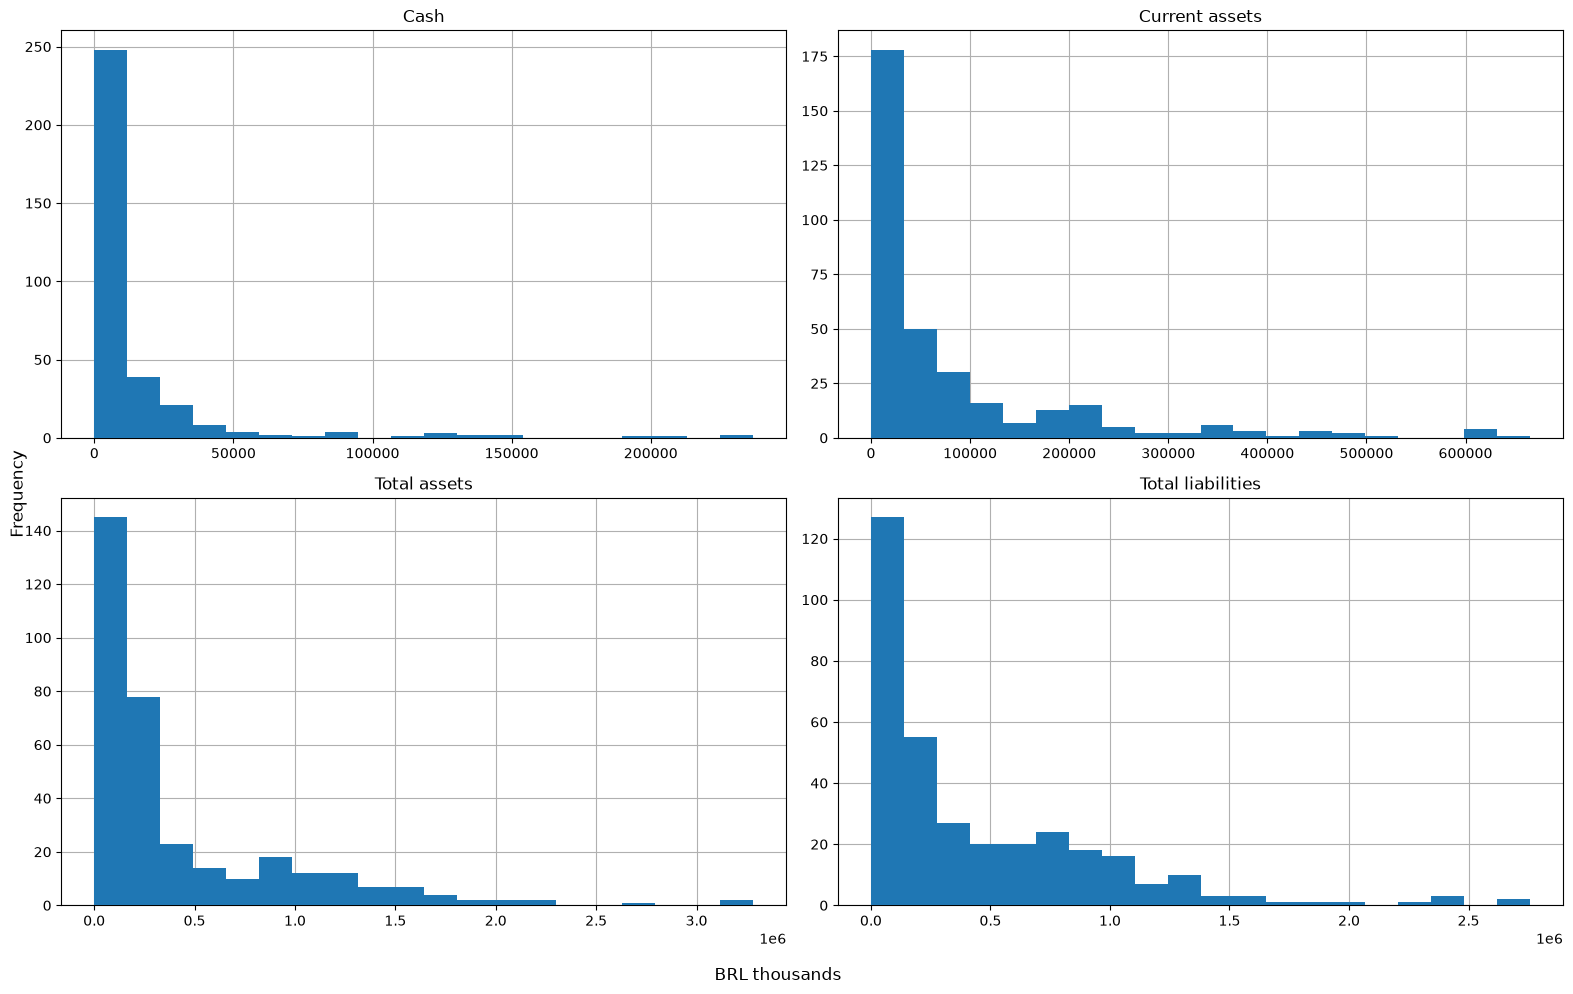

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

df_copy['cash'].hist(bins=20, ax=axes[0, 0], zorder=3)
axes[0, 0].set_title('Cash')

df_copy['current_assets'].hist(bins=20, ax=axes[0, 1], zorder=3)
axes[0, 1].set_title('Current assets')

df_copy['total_assets'].hist(bins=20, ax=axes[1, 0], zorder=3)
axes[1, 0].set_title('Total assets')

df_copy['total_liabilities'].hist(bins=20, ax=axes[1, 1], zorder=3)
axes[1, 1].set_title('Total liabilities')

fig.supxlabel('BRL thousands')
fig.supylabel('Frequency')


plt.tight_layout()
plt.show()

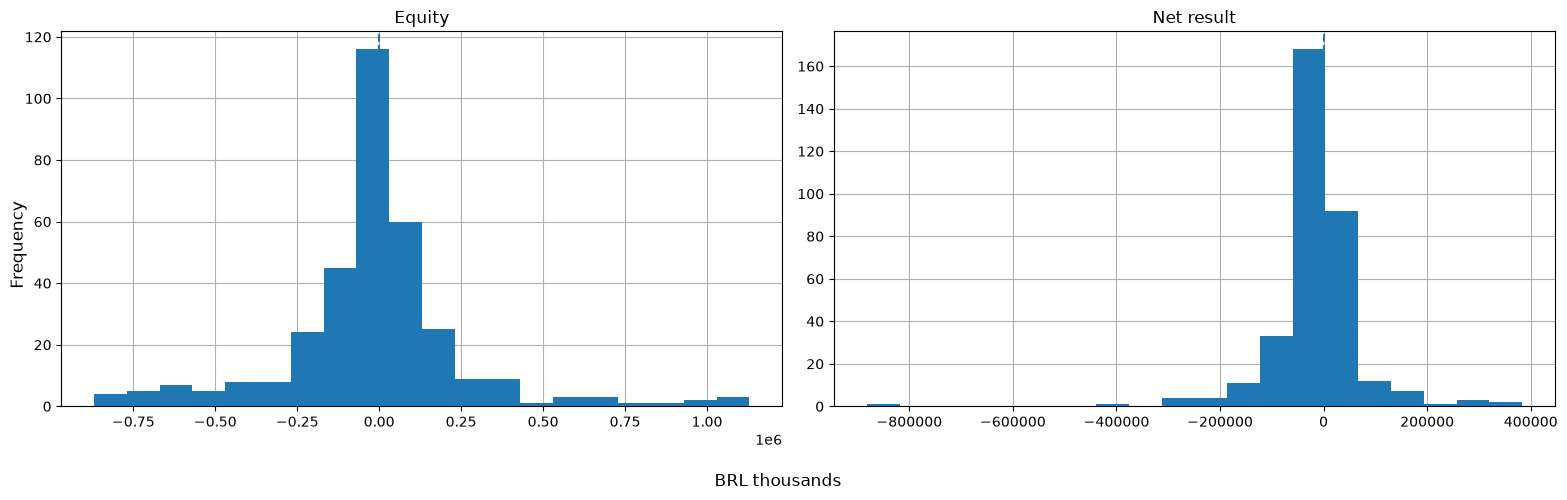

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df_copy['equity'].hist(bins=20, ax=axes[0], zorder=3)
axes[0].axvline(0, linestyle='--')
axes[0].set_title('Equity')

df_copy['net_result'].hist(bins=20, ax=axes[1], zorder=3)
axes[1].axvline(0, linestyle='--')
axes[1].set_title('Net result')

fig.supxlabel('BRL thousands')
fig.supylabel('Frequency')

plt.tight_layout()
plt.show()

Absolute values vary substantially across clubs. Relative indicators are more useful for comparing financial fragility.

## Financial indicators

In [7]:
df_copy['current_liquidity'] = df_copy['current_assets'] / df_copy['current_liabilities'].replace(0, np.nan)
df_copy['immediate_liquidity'] = df_copy['cash'] / df_copy['current_liabilities'].replace(0, np.nan)
df_copy['liability_ratio'] = df_copy['total_liabilities'] / df_copy['total_assets'].replace(0, np.nan)
df_copy['return_on_assets'] = df_copy['net_result'] / df_copy['total_assets'].replace(0, np.nan)
df_copy['working_capital'] = df_copy['current_assets'] - df_copy['current_liabilities']
df_copy['negative_equity'] = np.where(
    df_copy['equity'] < 0,
    1,
    0
)

### Liquidity

In [8]:
df_copy[['current_liquidity', 'immediate_liquidity', 'working_capital']].describe()

,current_liquidity,immediate_liquidity,working_capital
count,339.00,339.00,339.00
mean,0.95,0.42,-109476.77
std,2.98,2.48,168947.95
min,0.00,0.00,-1147019.00
25%,0.16,0.01,-180708.38
50%,0.36,0.03,-50153.71
75%,0.69,0.14,-5720.52
max,41.39,41.14,218760.00


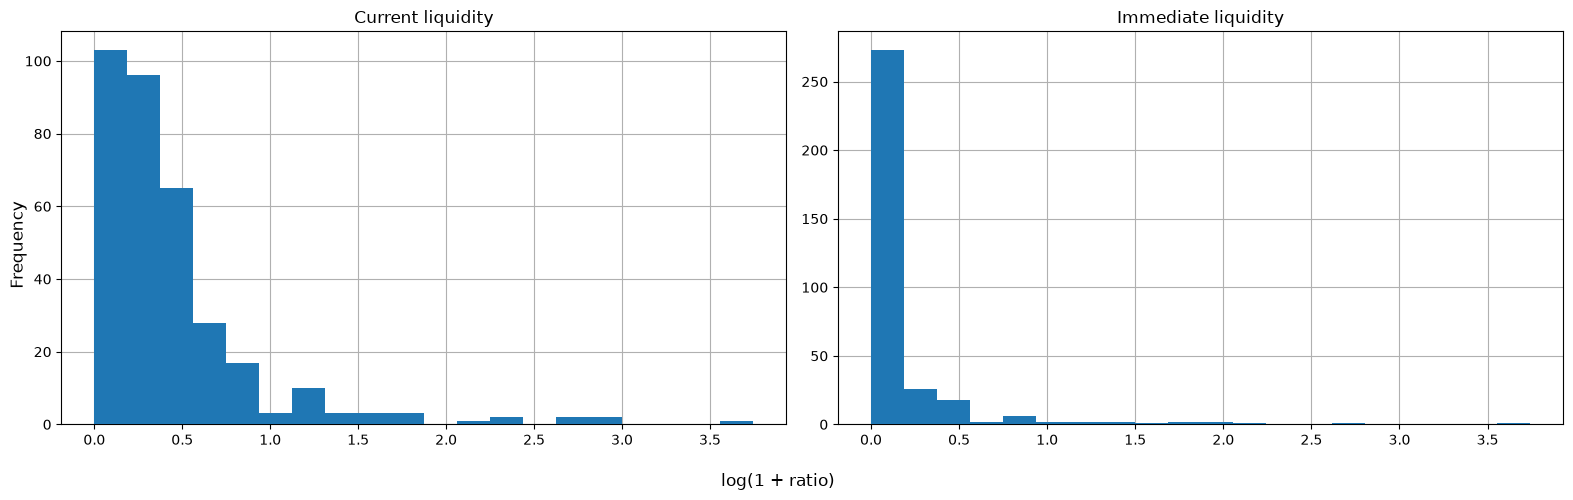

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

np.log1p(df_copy['current_liquidity']).hist(bins=20, ax=axes[0], zorder=3)
axes[0].set_title('Current liquidity')


np.log1p(df_copy['immediate_liquidity']).hist(bins=20, ax=axes[1], zorder=3)
axes[1].set_title('Immediate liquidity')

fig.supxlabel('log(1 + ratio)')
fig.supylabel('Frequency')

plt.tight_layout()
plt.show()

The liquidity ratios are shown on a log(1 + x) scale to reduce the effect of extreme values without removing observations.

In [10]:
low_liquidity = (
df_copy.groupby('fiscal_year')['current_liquidity']
    .apply(lambda x: (x < 1).mean() * 100)
)

low_liquidity

fiscal_year
2016   87.88
2017   87.88
2018   90.91
2019   96.97
2020   88.57
2021   88.57
2022   82.86
2023   71.43
2024   73.53
2025   81.82
Name: current_liquidity, dtype: float64

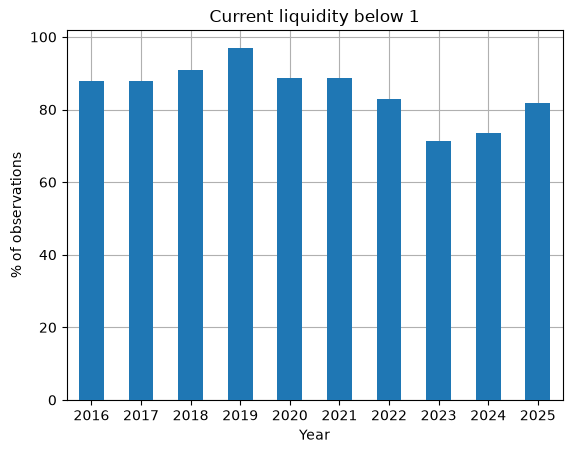

In [11]:
low_liquidity.plot(kind='bar', rot=0, zorder=3)

plt.title('Current liquidity below 1')
plt.xlabel('Year')
plt.ylabel('% of observations')

plt.grid()
plt.show()

The share of observations with current liquidity below 1 decreased from 2021 to 2023, increased slightly in 2024, and increased further in 2025. Even in 2023, the best year in this window, more than 70% of observations had current assets below current liabilities.

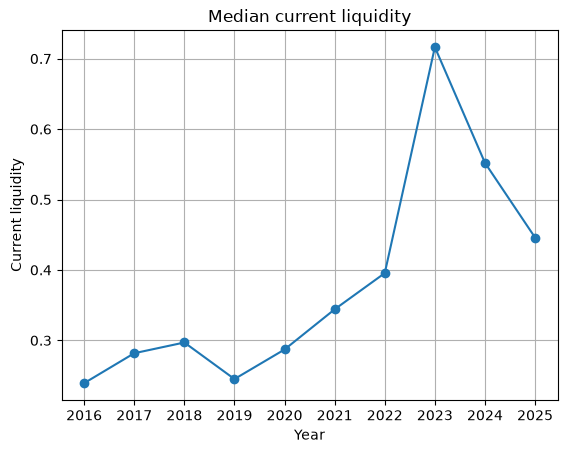

In [12]:
median_liquidity = (
    df_copy.groupby('fiscal_year')['current_liquidity']
    .median()
)

median_liquidity.plot(marker='o')

plt.title('Median current liquidity')
plt.xlabel('Year')
plt.ylabel('Current liquidity')
plt.xticks(median_liquidity.index)

plt.grid()
plt.show()

Median current liquidity improved considerably from 2021 to 2023, then declined in both 2024 and 2025. The median remained below 1 in every year.

### Solvency

In [13]:
df_copy['liability_ratio'].describe()

count   339.00
mean      1.43
std       1.50
min       0.03
25%       0.72
50%       1.03
75%       1.44
max       9.74
Name: liability_ratio, dtype: float64

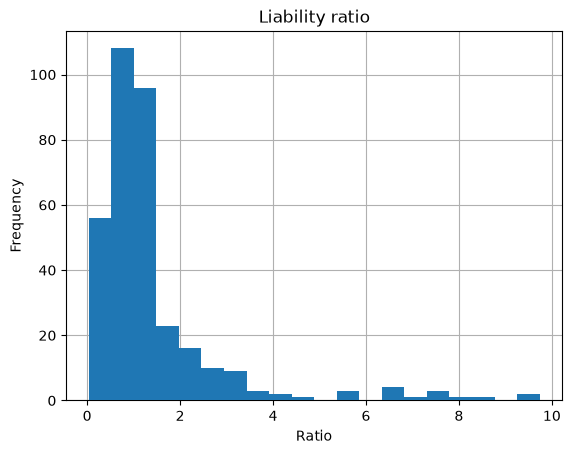

In [14]:
df_copy['liability_ratio'].hist(bins=20, zorder=3)

plt.title('Liability ratio')
plt.xlabel('Ratio')
plt.ylabel('Frequency')

plt.show()

In [15]:
negative_equity_by_year = (
    df_copy.groupby('fiscal_year')['negative_equity']
    .mean()
    * 100
)

negative_equity_by_year

fiscal_year
2016   51.52
2017   54.55
2018   54.55
2019   60.61
2020   60.00
2021   57.14
2022   42.86
2023   34.29
2024   47.06
2025   54.55
Name: negative_equity, dtype: float64

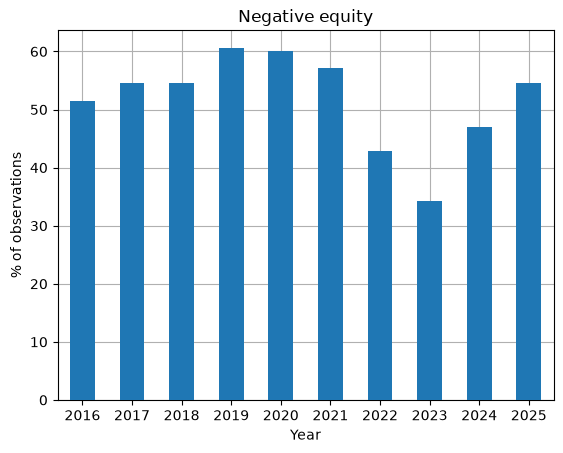

In [16]:
negative_equity_by_year.plot(kind='bar', rot=0, zorder=3)

plt.title('Negative equity')
plt.xlabel('Year')
plt.ylabel('% of observations')

plt.grid()
plt.show()

The share of observations with negative equity decreased from 2021 to 2023, but increased again in 2024 and 2025. In 2025, more than half of the observations had liabilities greater than assets.

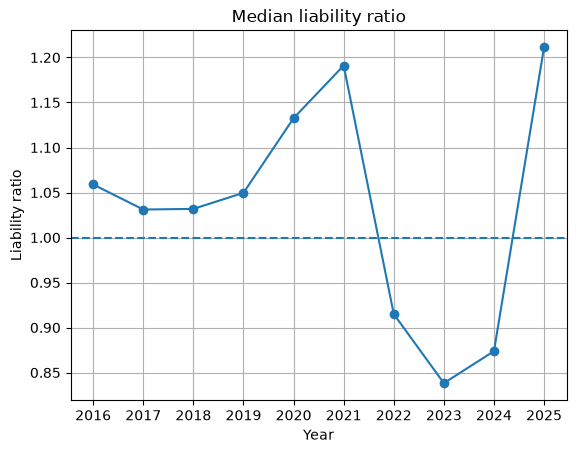

In [17]:
median_liability_ratio = (
    df_copy.groupby('fiscal_year')['liability_ratio']
    .median()
)

median_liability_ratio.plot(marker='o')

plt.axhline(1, linestyle='--')
plt.title('Median liability ratio')
plt.xlabel('Year')
plt.ylabel('Liability ratio')
plt.xticks(median_liability_ratio.index)

plt.grid()
plt.show()

Median liability ratio decreased from 2021 to 2023, indicating an improvement in solvency, and remained below 1 in 2024. In 2025, it increased sharply to its highest level in the period, with median liabilities exceeding total assets.

### Profitability

In [18]:
df_copy['return_on_assets'].describe()

count   339.00
mean     -0.08
std       0.47
min      -5.04
25%      -0.12
50%      -0.01
75%       0.06
max       1.06
Name: return_on_assets, dtype: float64

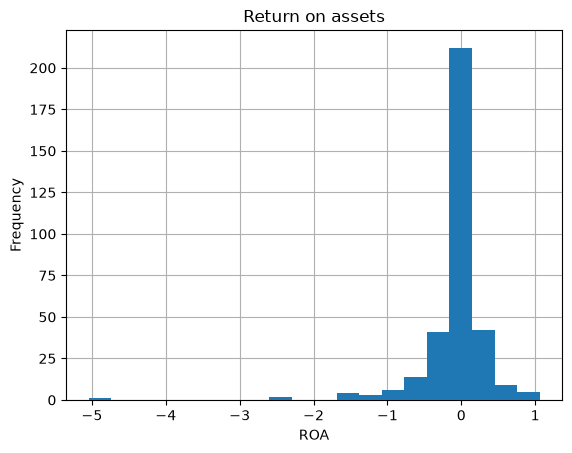

In [19]:
df_copy['return_on_assets'].hist(bins=20, zorder=3)

plt.title('Return on assets')
plt.xlabel('ROA')
plt.ylabel('Frequency')

plt.show()

Return on assets is concentrated around zero, with more extreme negative than positive outcomes. Some observations cover periods shorter than 12 months due to transitions to SAFs, so ROA should be interpreted with caution in these cases.

In [20]:
loss_by_year = (
    df_copy.groupby('fiscal_year')['net_result']
    .apply(lambda x: (x < 0).mean() * 100)
)

loss_by_year

fiscal_year
2016   36.36
2017   57.58
2018   48.48
2019   54.55
2020   71.43
2021   48.57
2022   42.86
2023   40.00
2024   73.53
2025   66.67
Name: net_result, dtype: float64

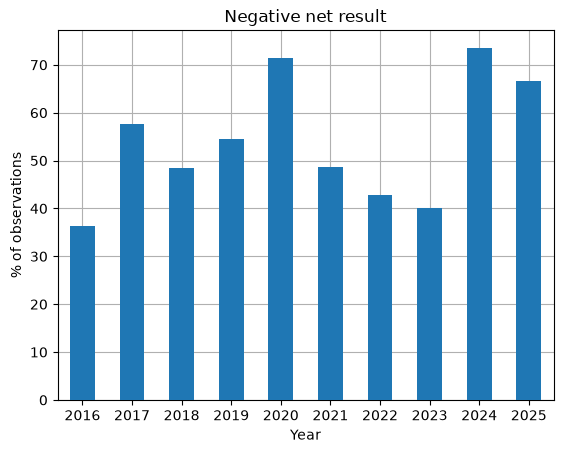

In [21]:
loss_by_year.plot(kind='bar', rot=0, zorder=3)

plt.title('Negative net result')
plt.xlabel('Year')
plt.ylabel('% of observations')

plt.grid()
plt.show()

The share of observations with a negative net result decreased from 48.6% in 2021 to 40.0% in 2023, then increased sharply to 73.5% in 2024 and remained high at 66.7% in 2025.

In [22]:
loss_rate = (
    df_copy.groupby('club')['net_result']
    .apply(lambda x: (x < 0).mean() * 100)
)

loss_rate.value_counts().sort_index()

net_result
10.00     2
20.00     3
22.22     1
30.00     2
40.00     4
44.44     1
50.00     3
55.56     1
60.00     7
70.00     2
71.43     1
80.00     2
85.71     1
87.50     1
90.00     3
100.00    1
Name: count, dtype: int64

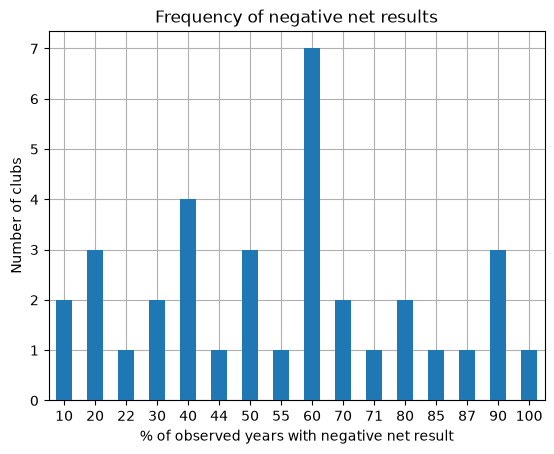

In [23]:
loss_rate.value_counts().sort_index().rename(index=int).plot(kind='bar', rot=0, zorder=3)

plt.title('Frequency of negative net results')
plt.xlabel('% of observed years with negative net result')
plt.ylabel('Number of clubs')

plt.grid()
plt.show()

Negative results are recurrent for a substantial share of the clubs. Eighteen of the 35 clubs (51.4%) reported losses in at least 60% of their observed years.

## Relationships between indicators

In [24]:
df_copy[['current_liquidity', 'immediate_liquidity', 'liability_ratio', 'return_on_assets']].corr()

,current_liquidity,immediate_liquidity,liability_ratio,return_on_assets
current_liquidity,1.00,0.91,-0.15,0.14
immediate_liquidity,0.91,1.00,-0.11,0.08
liability_ratio,-0.15,-0.11,1.00,-0.49
return_on_assets,0.14,0.08,-0.49,1.00


Current and immediate liquidity are strongly correlated, as expected, while the relationships between liquidity, solvency and profitability are weaker. The strongest cross-dimension relationship is between liability ratio and return on assets, with a moderate negative correlation.

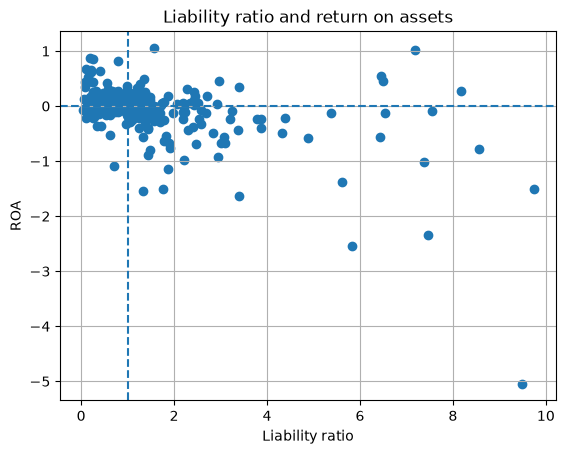

In [25]:
plt.scatter(df_copy['liability_ratio'], df_copy['return_on_assets'])

plt.axvline(1, linestyle='--')
plt.axhline(0, linestyle='--')

plt.title('Liability ratio and return on assets')
plt.xlabel('Liability ratio')
plt.ylabel('ROA')

plt.grid()
plt.show()

In [26]:
df_copy[['liability_ratio', 'return_on_assets']].corr(method='spearman')

,liability_ratio,return_on_assets
liability_ratio,1.00,-0.34
return_on_assets,-0.34,1.00


Liability ratio and return on assets show a negative association. The Pearson correlation is -0.49 and the Spearman correlation is -0.34, indicating a stronger linear than rank-based relationship in the current sample.

## Combined financial fragility

Combined fragility indicates current liquidity below 1, negative equity and a negative net result simultaneously. It is an exploratory measure, not a credit risk score.

In [27]:
df_copy['combined_fragility'] = (
    (df_copy['current_liquidity'] < 1) &
    (df_copy['negative_equity'] == 1) &
    (df_copy['net_result'] < 0)
)

combined_fragility_by_year = (
    df_copy.groupby('fiscal_year')['combined_fragility']
    .mean()
    * 100
)

combined_fragility_by_year

fiscal_year
2016   21.21
2017   30.30
2018   27.27
2019   36.36
2020   54.29
2021   34.29
2022   17.14
2023   20.00
2024   35.29
2025   39.39
Name: combined_fragility, dtype: float64

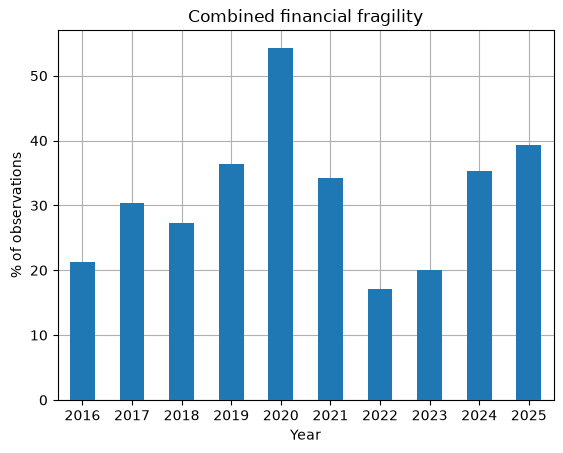

In [28]:
combined_fragility_by_year.plot(kind='bar', rot=0, zorder=3)

plt.title('Combined financial fragility')
plt.xlabel('Year')
plt.ylabel('% of observations')

plt.grid()
plt.show()

Combined financial fragility fell to 17.1% in 2022, then increased to 20.0% in 2023, 35.3% in 2024, and 39.4% in 2025. The condition therefore became materially more frequent again in the final two years.

In [29]:
fragility_rate = (
    df_copy.groupby('club')['combined_fragility']
    .mean()
    * 100
)

fragility_rate.value_counts().sort_index()

combined_fragility
0.00     8
10.00    2
11.11    1
20.00    4
22.22    1
30.00    3
40.00    5
50.00    3
60.00    3
62.50    1
70.00    2
71.43    1
80.00    1
Name: count, dtype: int64

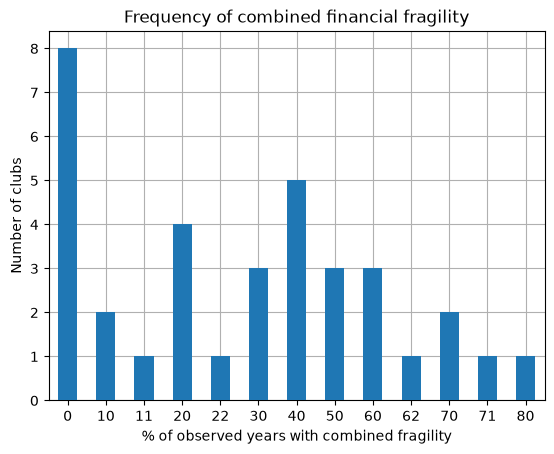

In [30]:
fragility_rate.value_counts().sort_index().rename(index=int).plot(kind='bar', rot=0, zorder=3)

plt.title('Frequency of combined financial fragility')
plt.xlabel('% of observed years with combined fragility')
plt.ylabel('Number of clubs')

plt.grid()
plt.show()

Combined financial fragility is recurrent for part of the clubs, although its frequency varies substantially across the observed period.

## Main findings

- Liquidity remained weak throughout the period, with median current liquidity below 1 in every year.
- Liquidity improved through 2023, then deteriorated in both 2024 and 2025.
- Solvency followed a similar pattern, with a sharp increase in the median liability ratio in 2025.
- Negative results became much more frequent in 2024 and remained high in 2025.
- Losses are recurrent for a relevant share of the clubs, rather than isolated events.
- Liquidity, solvency and profitability capture different aspects of financial fragility.
- Combined financial fragility became more frequent in 2024–2025 and is persistent for part of the sample.